# 02 — Custom CNN Baseline

**Project:** Brain MRI Image Classification and Explainable AI  
**Notebook goal:** train a compact CNN from scratch, select the checkpoint using validation macro-F1, and report classification performance on the provided test set and an additional test subset with exact training/test duplicates removed.

## What this notebook produces

- `models/custom_cnn.pt` — best validation checkpoint, class mapping, and model configuration
- `results/model_data_split.csv` — reusable train/validation/test split for the later ResNet and ViT notebooks
- `results/custom_cnn_history.csv` — per-epoch losses and validation metrics
- `results/custom_cnn_metrics.json` — final test metrics and experiment metadata
- `results/custom_cnn_classification_report.csv` — class-wise test metrics
- `results/custom_cnn_predictions.csv` — predictions and class probabilities for both test evaluations
- `results/visualizations/custom_cnn_learning_curves.png` and confusion-matrix images

## Before running

1. Complete `01_eda_and_data_audit.ipynb` first if possible. This notebook reuses `results/image_inventory.csv` when available, but can build its own inventory if needed.
2. Download the [Brain Tumor MRI Dataset by Masoud Nickparvar from Kaggle](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset) and extract it under `data/`.
3. Run all cells from top to bottom. The first run may take time depending on hardware.

> **Evaluation rules:** only the provided training split is divided into training and validation data. Validation macro-F1 chooses the checkpoint. The official test set is evaluated after training and is never used for checkpoint selection. Because published copies may contain overlapping images, the notebook also reports an exact-duplicate-filtered test result. Exact-hash filtering does not remove all possible near-duplicates and does not establish patient-level independence.

> **Research/education only:** this is an image-classification exercise, not a clinical diagnostic tool. A model prediction or heatmap is not medical advice.

## 1. Imports and reproducibility

Install the project requirements from the project root with `pip install -r requirements.txt`. This baseline uses PyTorch and torchvision; the implementation stays intentionally small and understandable before introducing ResNet and ViT in later notebooks.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("PyTorch:", torch.__version__)
print("scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

d:\computer vision\Brain-MRI-Classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.5.1+cu121
scikit-learn: 1.9.1
CUDA available: True


## 2. Configuration and output paths

Defaults are suitable for a first baseline. If you have a CUDA GPU, the notebook uses it automatically. `NUM_WORKERS = 0` is deliberate for compatibility with Windows and notebooks; you can increase it later if your environment supports multiprocessing reliably.

In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD
DATA_BASE = PROJECT_ROOT / "data"  # Change this if your dataset is stored elsewhere.
RESULTS_DIR = PROJECT_ROOT / "results"
VIS_DIR = RESULTS_DIR / "visualizations"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (RESULTS_DIR, VIS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
TRAIN_NAMES = {"training", "train"}
TEST_NAMES = {"testing", "test"}

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 4
VALIDATION_FRACTION = 0.20
NUM_WORKERS = 0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH = MODELS_DIR / "custom_cnn.pt"
SPLIT_PATH = RESULTS_DIR / "model_data_split.csv"
HISTORY_PATH = RESULTS_DIR / "custom_cnn_history.csv"
METRICS_PATH = RESULTS_DIR / "custom_cnn_metrics.json"
REPORT_PATH = RESULTS_DIR / "custom_cnn_classification_report.csv"
PREDICTIONS_PATH = RESULTS_DIR / "custom_cnn_predictions.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset search root:", DATA_BASE)
print("Output device:", DEVICE)
print("Image size:", IMG_SIZE, "| batch size:", BATCH_SIZE, "| max epochs:", EPOCHS)

Project root: D:\computer vision\Brain-MRI-Classification
Dataset search root: D:\computer vision\Brain-MRI-Classification\data
Output device: cuda
Image size: 224 | batch size: 32 | max epochs: 15


## 3. Locate the dataset

The code searches under `data/` for a matching `Training`/`Testing` or `train`/`test` directory pair. Each split must contain one subfolder per class.

In [3]:
def class_dirs_with_images(split_dir: Path):
    if not split_dir.is_dir():
        return []
    found = []
    for child in sorted(split_dir.iterdir()):
        if child.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            for p in child.rglob("*")
        ):
            found.append(child)
    return found


def find_split_directories(search_root: Path):
    if not search_root.exists():
        raise FileNotFoundError(
            f"Dataset root not found: {search_root}. Download/extract the Kaggle dataset under data/, "
            "or update DATA_BASE in the configuration cell."
        )
    candidates = [p for p in search_root.rglob("*") if p.is_dir()]
    candidates.append(search_root)
    train_dirs = [p for p in candidates if p.name.lower() in TRAIN_NAMES and class_dirs_with_images(p)]
    test_dirs = [p for p in candidates if p.name.lower() in TEST_NAMES and class_dirs_with_images(p)]
    pairs = [(tr, te) for tr in train_dirs for te in test_dirs if tr.parent == te.parent]
    if not pairs:
        raise FileNotFoundError(
            "Could not find matching Training/Testing (or train/test) folders with class subfolders. "
            f"Search root: {search_root}. See the dataset layout in README.md."
        )
    pairs.sort(key=lambda pair: len(pair[0].parts) + len(pair[1].parts))
    return pairs[0]


TRAIN_DIR, TEST_DIR = find_split_directories(DATA_BASE)
DATASET_ROOT = TRAIN_DIR.parent
print("Dataset root:", DATASET_ROOT)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)
print("Training class folders:", [p.name for p in class_dirs_with_images(TRAIN_DIR)])
print("Testing class folders:", [p.name for p in class_dirs_with_images(TEST_DIR)])

Dataset root: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset
Training directory: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Training
Testing directory: D:\computer vision\Brain-MRI-Classification\data\brain-tumor-mri-dataset\Testing
Training class folders: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing class folders: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 4. Build a valid image index

If notebook 01 has already exported `results/image_inventory.csv`, its valid/invalid flags and SHA-256 hashes are reused where the relative paths match. Otherwise, this cell verifies and hashes the images itself. Images that cannot be opened are skipped and recorded.

In [4]:
def sha256_file(path: Path, block_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as file_obj:
        for block in iter(lambda: file_obj.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def parse_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    return str(value).strip().lower() in {"true", "1", "yes", "y"}


inventory_path = RESULTS_DIR / "image_inventory.csv"
inventory_lookup = {}
if inventory_path.exists():
    try:
        inventory_df = pd.read_csv(inventory_path)
        required_columns = {"relative_path", "is_valid", "sha256"}
        if required_columns.issubset(inventory_df.columns):
            inventory_lookup = {
                str(row["relative_path"]): row
                for row in inventory_df.to_dict("records")
            }
            print(f"Loaded metadata from notebook 01: {len(inventory_lookup):,} inventory rows")
        else:
            print("Notebook 01 inventory has unexpected columns; file metadata will be rebuilt.")
    except Exception as exc:
        print("Could not read notebook 01 inventory; rebuilding metadata.", repr(exc))


def collect_split_rows(split_dir: Path, split_name: str):
    records, bad_records = [], []
    for class_dir in class_dirs_with_images(split_dir):
        class_name = class_dir.name.strip().lower()
        for path in sorted(class_dir.rglob("*")):
            if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            relative_path = path.relative_to(DATASET_ROOT).as_posix()
            old = inventory_lookup.get(relative_path)
            if old is not None and not parse_bool(old.get("is_valid", True)):
                bad_records.append({"split": split_name, "class_name": class_name,
                                    "relative_path": relative_path, "reason": "Marked invalid in notebook 01"})
                continue
            try:
                with Image.open(path) as image_obj:
                    image_obj.verify()
                digest = None
                if old is not None and pd.notna(old.get("sha256")) and str(old.get("sha256")).strip():
                    digest = str(old["sha256"])
                if digest is None:
                    digest = sha256_file(path)
                records.append({
                    "original_split": split_name,
                    "class_name": class_name,
                    "relative_path": relative_path,
                    "path": str(path.resolve()),
                    "sha256": digest,
                })
            except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as exc:
                bad_records.append({"split": split_name, "class_name": class_name,
                                    "relative_path": relative_path,
                                    "reason": f"{type(exc).__name__}: {exc}"})
    return records, bad_records


train_records, bad_train = collect_split_rows(TRAIN_DIR, "train")
test_records, bad_test = collect_split_rows(TEST_DIR, "test")
index_df = pd.DataFrame(train_records + test_records)
bad_df = pd.DataFrame(bad_train + bad_test)

if index_df.empty:
    raise RuntimeError("No readable images were found. Check DATA_BASE and the class-folder structure.")
if not bad_df.empty:
    bad_path = RESULTS_DIR / "custom_cnn_invalid_images.csv"
    bad_df.to_csv(bad_path, index=False)
    print(f"Skipped {len(bad_df):,} unreadable/invalid image(s). Details: {bad_path}")

train_classes = set(index_df.loc[index_df["original_split"] == "train", "class_name"])
test_classes = set(index_df.loc[index_df["original_split"] == "test", "class_name"])
if train_classes != test_classes:
    raise ValueError(f"Train/test classes do not match. Train={sorted(train_classes)}, test={sorted(test_classes)}")
CLASS_NAMES = sorted(train_classes, key=str.casefold)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

print("Readable images:", f"{len(index_df):,}")
print("Classes:", CLASS_NAMES)
print("Class-to-index mapping:", CLASS_TO_IDX)
print("Original training rows:", int((index_df.original_split == "train").sum()))
print("Original testing rows:", int((index_df.original_split == "test").sum()))
display(index_df.groupby(["original_split", "class_name"]).size().rename("images").reset_index())

Loaded metadata from notebook 01: 7,200 inventory rows
Readable images: 7,200
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class-to-index mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Original training rows: 5600
Original testing rows: 1600


,original_split,class_name,images
0,test,glioma,400
1,test,meningioma,400
2,test,notumor,400
3,test,pituitary,400
4,train,glioma,1400
5,train,meningioma,1400
6,train,notumor,1400
7,train,pituitary,1400


## 5. Handle exact-hash label conflicts and create a leakage-aware split

Two rules are used here:

1. If byte-identical images have conflicting class labels, they are removed from this experiment rather than arbitrarily choosing a label. They are listed in `results/custom_cnn_conflicting_hashes_excluded.csv`.
2. The original training data is split into training and validation folds using `StratifiedGroupKFold`, with the SHA-256 hash as the group. This keeps exact copies together when constructing the validation set.

The original test folder remains untouched for the final evaluation. The split manifest is saved for reuse by ResNet-18 and ViT so those models can use the same training/validation split.

In [5]:
# Exclude ambiguous exact-image groups when the same hash has different labels.
labels_per_hash = index_df.groupby("sha256")["class_name"].nunique()
conflicting_hashes = set(labels_per_hash[labels_per_hash > 1].index)
if conflicting_hashes:
    conflict_df = index_df[index_df["sha256"].isin(conflicting_hashes)].copy()
    conflict_path = RESULTS_DIR / "custom_cnn_conflicting_hashes_excluded.csv"
    conflict_df.drop(columns=["path"]).to_csv(conflict_path, index=False)
    print(f"WARNING: {len(conflicting_hashes)} exact-hash group(s) have conflicting labels.")
    print("All rows in these groups will be excluded; review:", conflict_path)
    index_df = index_df[~index_df["sha256"].isin(conflicting_hashes)].copy()
else:
    print("No exact-hash groups with conflicting labels detected.")

original_train_df = index_df[index_df["original_split"] == "train"].copy().reset_index(drop=True)
official_test_df = index_df[index_df["original_split"] == "test"].copy().reset_index(drop=True)
if original_train_df.empty or official_test_df.empty:
    raise RuntimeError("Training or test split is empty after invalid/conflicting rows are excluded.")

if set(original_train_df["class_name"]) != set(CLASS_NAMES):
    raise RuntimeError("At least one class has no usable image in the original training split.")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
candidates = []
y_all = original_train_df["class_name"].to_numpy()
groups_all = original_train_df["sha256"].to_numpy()
for fold_id, (train_idx, val_idx) in enumerate(sgkf.split(original_train_df, y_all, groups_all), start=1):
    fold_train = original_train_df.iloc[train_idx]
    fold_val = original_train_df.iloc[val_idx]
    if set(fold_train["class_name"]) != set(CLASS_NAMES) or set(fold_val["class_name"]) != set(CLASS_NAMES):
        continue
    val_fraction = len(fold_val) / len(original_train_df)
    overall_dist = original_train_df["class_name"].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
    val_dist = fold_val["class_name"].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
    distribution_error = float((overall_dist - val_dist).abs().mean())
    score = abs(val_fraction - VALIDATION_FRACTION) + distribution_error
    candidates.append((score, fold_id, train_idx, val_idx, val_fraction, distribution_error))

if not candidates:
    raise RuntimeError(
        "Could not create a group-aware train/validation split containing every class. "
        "Inspect class counts and exact-duplicate groups in notebook 01 before proceeding."
    )

candidates.sort(key=lambda item: item[0])
_, selected_fold, train_idx, val_idx, selected_val_fraction, selected_dist_error = candidates[0]
train_df = original_train_df.iloc[train_idx].copy().reset_index(drop=True)
val_df = original_train_df.iloc[val_idx].copy().reset_index(drop=True)
test_df = official_test_df.copy().reset_index(drop=True)

# This subset is for a secondary test report only. It is not used for selection or tuning.
original_train_hashes = set(original_train_df["sha256"])
test_exact_filtered_df = test_df[~test_df["sha256"].isin(original_train_hashes)].copy().reset_index(drop=True)

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
assert train_hashes.isdisjoint(val_hashes), "Exact-hash leakage between train and validation was detected."

train_df["model_split"] = "train"
val_df["model_split"] = "validation"
test_df["model_split"] = "test"
manifest_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
manifest_df[["original_split", "model_split", "class_name", "relative_path", "sha256"]].to_csv(SPLIT_PATH, index=False)

print(f"Selected StratifiedGroupKFold fold: {selected_fold}")
print(f"Validation fraction: {selected_val_fraction:.3f} (target {VALIDATION_FRACTION:.2f})")
print(f"Validation class-distribution error (mean absolute difference): {selected_dist_error:.4f}")
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Official test: {len(test_df):,}")
print(f"Test after exact training/test hash overlap removal: {len(test_exact_filtered_df):,}")
print("Saved shared split manifest:", SPLIT_PATH)
print("Exact-hash train/validation overlap:", len(train_hashes.intersection(val_hashes)))
display(pd.concat([
    train_df.assign(model_split="train"),
    val_df.assign(model_split="validation"),
    test_df.assign(model_split="test"),
]).groupby(["model_split", "class_name"]).size().rename("images").reset_index())

No exact-hash groups with conflicting labels detected.
Selected StratifiedGroupKFold fold: 1
Validation fraction: 0.200 (target 0.20)
Validation class-distribution error (mean absolute difference): 0.0000
Train: 4,480 | Validation: 1,120 | Official test: 1,600
Test after exact training/test hash overlap removal: 1,600
Saved shared split manifest: D:\computer vision\Brain-MRI-Classification\results\model_data_split.csv
Exact-hash train/validation overlap: 0


,model_split,class_name,images
0,test,glioma,400
1,test,meningioma,400
2,test,notumor,400
3,test,pituitary,400
4,train,glioma,1120
5,train,meningioma,1120
6,train,notumor,1120
7,train,pituitary,1120
8,validation,glioma,280
9,validation,meningioma,280


## 6. Image transforms and PyTorch datasets

Images are converted to RGB and resized to 224 × 224. This notebook applies mild geometric augmentation only to training examples. Validation and test transforms are deterministic. The same class mapping is used for every split.

In [6]:
TRAIN_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])


class BrainMRIDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, class_to_idx: dict, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        path = Path(row["path"])
        with Image.open(path) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        label = self.class_to_idx[row["class_name"]]
        return image, label


train_dataset = BrainMRIDataset(train_df, CLASS_TO_IDX, TRAIN_TRANSFORM)
val_dataset = BrainMRIDataset(val_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_dataset = BrainMRIDataset(test_df, CLASS_TO_IDX, EVAL_TRANSFORM)
test_exact_filtered_dataset = BrainMRIDataset(test_exact_filtered_df, CLASS_TO_IDX, EVAL_TRANSFORM)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
}
train_loader = DataLoader(train_dataset, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_common)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_common)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_common)
test_exact_filtered_loader = DataLoader(test_exact_filtered_dataset, shuffle=False, **loader_common)

print("Dataset sizes:", {"train": len(train_dataset), "validation": len(val_dataset),
                         "test": len(test_dataset), "test_exact_filtered": len(test_exact_filtered_dataset)})

Dataset sizes: {'train': 4480, 'validation': 1120, 'test': 1600, 'test_exact_filtered': 1600}


## 7. Define the custom CNN

The network has four convolutional blocks, batch normalization, ReLU, max-pooling, adaptive global average pooling, and a small fully connected classification head. This is intentionally a compact baseline rather than a sophisticated architecture.

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

    def forward(self, x):
        return self.block(x)


class CustomBrainMRICNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.40),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model = CustomBrainMRICNN(num_classes=len(CLASS_NAMES)).to(DEVICE)
num_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model)
print(f"Total parameters: {num_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

CustomBrainMRICNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNor

## 8. Training and evaluation helpers

The training loop records loss and validation metrics each epoch. Macro-F1 is used for checkpoint selection so that each class contributes equally to the selection metric. The final test data is not consulted here.

In [8]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    total = 0
    for images, labels in tqdm(loader, desc="Train", leave=False):
        images = images.to(device, non_blocking=(device.type == "cuda"))
        labels = labels.to(device, non_blocking=(device.type == "cuda"))
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        batch_size = labels.size(0)
        running_loss += float(loss.detach().item()) * batch_size
        total += batch_size
    return running_loss / max(total, 1)


def evaluate_model(model, loader, criterion, device, class_names):
    model.eval()
    running_loss = 0.0
    total = 0
    y_true, y_pred, y_prob = [], [], []
    forward_seconds = 0.0
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Evaluate", leave=False):
            images = images.to(device, non_blocking=(device.type == "cuda"))
            labels = labels.to(device, non_blocking=(device.type == "cuda"))
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            start_time = time.perf_counter()
            logits = model(images)
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            forward_seconds += time.perf_counter() - start_time
            loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)
            batch_size = labels.size(0)
            running_loss += float(loss.item()) * batch_size
            total += batch_size
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            y_prob.extend(probabilities.cpu().numpy().tolist())

    if total == 0:
        raise ValueError("Cannot evaluate an empty dataset.")
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    labels_all = list(range(len(class_names)))
    metrics = {
        "loss": float(running_loss / total),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
        "num_images": int(total),
        "forward_latency_ms_per_image": float(1000.0 * forward_seconds / total),
    }
    try:
        metrics["roc_auc_ovr_macro"] = float(
            roc_auc_score(y_true, y_prob, labels=labels_all, multi_class="ovr", average="macro")
        )
    except ValueError as exc:
        metrics["roc_auc_ovr_macro"] = None
        metrics["roc_auc_note"] = str(exc)
    return metrics, y_true, y_pred, y_prob

## 9. Train the CNN and select the best validation checkpoint

The default is at most 15 epochs with early stopping. To make a quick smoke test, temporarily set `EPOCHS = 1` and reduce `IMG_SIZE`/`BATCH_SIZE` in the configuration cell. For the final experiment, restore your intended settings and record them.

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

history_rows = []
best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_metrics, _, _, _ = evaluate_model(model, val_loader, criterion, DEVICE, CLASS_NAMES)
    scheduler.step(val_metrics["f1_macro"])
    current_lr = float(optimizer.param_groups[0]["lr"])
    epoch_seconds = time.perf_counter() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_f1_macro": val_metrics["f1_macro"],
        "val_roc_auc_ovr_macro": val_metrics.get("roc_auc_ovr_macro"),
        "learning_rate": current_lr,
        "epoch_seconds": float(epoch_seconds),
    }
    history_rows.append(row)
    pd.DataFrame(history_rows).to_csv(HISTORY_PATH, index=False)
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} "
        f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
        f"val_macro_f1={val_metrics['f1_macro']:.4f} lr={current_lr:.2e} "
        f"time={epoch_seconds:.1f}s"
    )

    if val_metrics["f1_macro"] > best_val_f1 + 1e-5:
        best_val_f1 = val_metrics["f1_macro"]
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "class_to_idx": CLASS_TO_IDX,
            "img_size": IMG_SIZE,
            "normalization_mean": [0.5, 0.5, 0.5],
            "normalization_std": [0.5, 0.5, 0.5],
            "architecture": "CustomBrainMRICNN",
            "seed": SEED,
            "best_epoch": best_epoch,
            "best_validation_macro_f1": best_val_f1,
            "config": {
                "batch_size": BATCH_SIZE,
                "epochs_requested": EPOCHS,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "validation_fraction_target": VALIDATION_FRACTION,
            },
        }, CHECKPOINT_PATH)
        print("  Saved new best checkpoint:", CHECKPOINT_PATH)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping: validation macro-F1 did not improve for {EARLY_STOPPING_PATIENCE} epochs.")
            break

history_df = pd.DataFrame(history_rows)
history_df.to_csv(HISTORY_PATH, index=False)
print(f"Best epoch: {best_epoch}; best validation macro-F1: {best_val_f1:.4f}")
print("History saved:", HISTORY_PATH)

Epoch 01/15 | train_loss=0.3139 val_loss=0.5570 val_acc=0.8214 val_macro_f1=0.8034 lr=1.00e-03 time=78.7s
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\custom_cnn.pt


Epoch 02/15 | train_loss=0.2867 val_loss=0.2967 val_acc=0.8920 val_macro_f1=0.8941 lr=1.00e-03 time=80.8s
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\custom_cnn.pt


Epoch 03/15 | train_loss=0.2810 val_loss=0.8996 val_acc=0.7304 val_macro_f1=0.7207 lr=1.00e-03 time=82.0s


Epoch 04/15 | train_loss=0.2579 val_loss=0.3240 val_acc=0.8911 val_macro_f1=0.8891 lr=1.00e-03 time=81.9s


Epoch 05/15 | train_loss=0.2475 val_loss=0.2794 val_acc=0.9000 val_macro_f1=0.9029 lr=1.00e-03 time=82.2s
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\custom_cnn.pt


...

Epoch 11/15 | train_loss=0.2059 val_loss=0.2290 val_acc=0.9179 val_macro_f1=0.9193 lr=5.00e-04 time=89.4s


Epoch 12/15 | train_loss=0.1529 val_loss=0.1629 val_acc=0.9437 val_macro_f1=0.9437 lr=5.00e-04 time=85.9s
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\custom_cnn.pt


Epoch 13/15 | train_loss=0.1560 val_loss=0.1646 val_acc=0.9500 val_macro_f1=0.9495 lr=5.00e-04 time=82.6s
  Saved new best checkpoint: D:\computer vision\Brain-MRI-Classification\models\custom_cnn.pt


Epoch 14/15 | train_loss=0.1470 val_loss=0.1993 val_acc=0.9286 val_macro_f1=0.9271 lr=5.00e-04 time=82.9s


Epoch 15/15 | train_loss=0.1344 val_loss=0.1804 val_acc=0.9384 val_macro_f1=0.9378 lr=5.00e-04 time=86.0s
Best epoch: 13; best validation macro-F1: 0.9495
History saved: D:\computer vision\Brain-MRI-Classification\results\custom_cnn_history.csv


## 10. Plot learning curves

Use these plots to check convergence, overfitting, and whether the model needs more or fewer epochs. Do not select a model based on the test set.

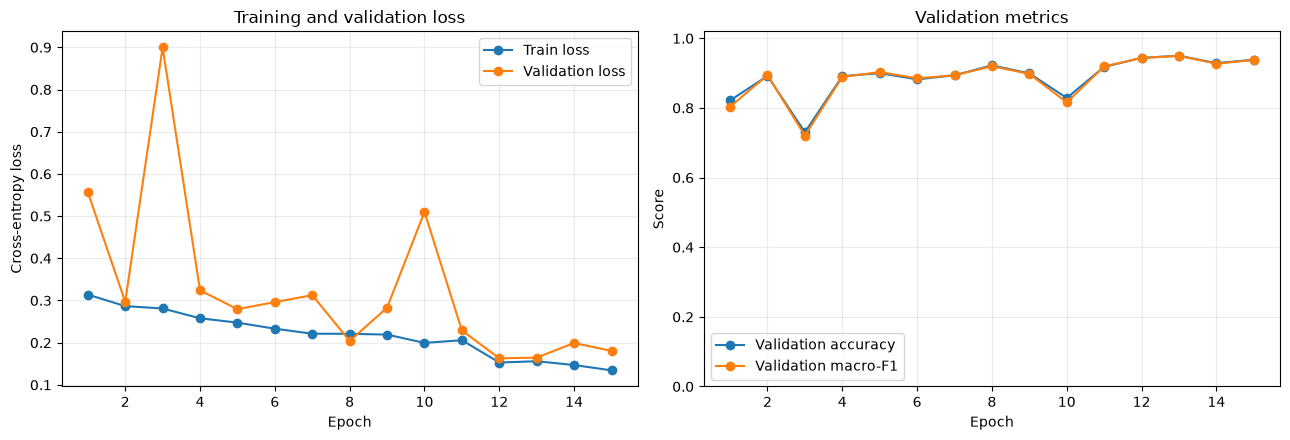

Saved: D:\computer vision\Brain-MRI-Classification\results\visualizations\custom_cnn_learning_curves.png


In [13]:
history_df = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].plot(history_df["epoch"], history_df["val_f1_macro"], marker="o", label="Validation macro-F1")
axes[1].set_title("Validation metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
curve_path = VIS_DIR / "custom_cnn_learning_curves.png"
plt.savefig(curve_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)

## 11. Load the best checkpoint

The checkpoint with the highest validation macro-F1 is reloaded before any test evaluation.

In [14]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class mapping does not match the current dataset. Retrain or restore the matching split/data.")
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()
print("Loaded checkpoint from epoch:", checkpoint["best_epoch"])
print("Checkpoint validation macro-F1:", f"{checkpoint['best_validation_macro_f1']:.4f}")

Loaded checkpoint from epoch: 13
Checkpoint validation macro-F1: 0.9495


## 12. Final test evaluation

**Run test evaluation only after model settings and checkpoint selection are finalized.** Two metrics are exported:

- **Official test:** all readable test images except ambiguous exact-hash groups with conflicting labels.
- **Exact-duplicate-filtered test:** the official test images after removing any image whose SHA-256 also appears in the original training folder.

The second result is a sensitivity analysis, not a guarantee of an independent or patient-level test set. The notebook does not automatically remove perceptual-hash candidates because similar MRI slices can be false positives; inspect candidate pairs from notebook 01 and record any manually reviewed exclusions separately.

In [15]:
def build_prediction_frame(frame, y_true, y_pred, y_prob, class_names, evaluation_name):
    output = pd.DataFrame({
        "evaluation": evaluation_name,
        "relative_path": frame["relative_path"].to_numpy(),
        "true_class": [class_names[i] for i in y_true],
        "predicted_class": [class_names[i] for i in y_pred],
        "correct": (y_true == y_pred),
    })
    for class_idx, class_name in enumerate(class_names):
        output[f"probability_{class_name}"] = y_prob[:, class_idx]
    return output


def save_confusion_matrix(y_true, y_pred, class_names, title, output_path):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ticks = np.arange(len(class_names))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(class_names, rotation=35, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    threshold = cm.max() / 2 if cm.size else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black")
    plt.tight_layout()
    plt.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.show()
    return cm


# Evaluation happens only now, after restoring the selected validation checkpoint.
official_metrics, y_test, pred_test, prob_test = evaluate_model(
    model, test_loader, criterion, DEVICE, CLASS_NAMES
)
official_predictions = build_prediction_frame(
    test_df, y_test, pred_test, prob_test, CLASS_NAMES, "official_test"
)
print("Official test metrics:")
display(pd.DataFrame([official_metrics]).T.rename(columns={0: "value"}))

Official test metrics:


,value
loss,0.671308
accuracy,0.880000
balanced_accuracy,0.880000
precision_macro,0.894981
recall_macro,0.880000
f1_macro,0.879795
num_images,1600.000000
forward_latency_ms_per_image,3.018000
roc_auc_ovr_macro,0.963533


In [16]:
# Secondary evaluation excluding exact test images already present in the original Training folder.
if len(test_exact_filtered_dataset) > 0:
    filtered_metrics, y_filtered, pred_filtered, prob_filtered = evaluate_model(
        model, test_exact_filtered_loader, criterion, DEVICE, CLASS_NAMES
    )
    filtered_predictions = build_prediction_frame(
        test_exact_filtered_df, y_filtered, pred_filtered, prob_filtered,
        CLASS_NAMES, "test_exact_duplicate_filtered"
    )
    print("Exact-duplicate-filtered test metrics:")
    display(pd.DataFrame([filtered_metrics]).T.rename(columns={0: "value"}))
else:
    filtered_metrics = None
    filtered_predictions = pd.DataFrame()
    print("No test images remain after exact train/test duplicate filtering; filtered metrics are not available.")

Exact-duplicate-filtered test metrics:


,value
loss,0.671308
accuracy,0.880000
balanced_accuracy,0.880000
precision_macro,0.894981
recall_macro,0.880000
f1_macro,0.879795
num_images,1600.000000
forward_latency_ms_per_image,3.145998
roc_auc_ovr_macro,0.963533


## 13. Class-wise report, confusion matrices, and predictions

Review per-class recall and the confusion matrix, not only the overall score. If the model mistakes one class for another, inspect those images manually in a later error-analysis step.

,precision,recall,f1-score,support
glioma,0.9624,0.7675,0.8540,400.00
meningioma,0.8883,0.7950,0.8391,400.00
notumor,0.7547,1.0000,0.8602,400.00
pituitary,0.9746,0.9575,0.9660,400.00
accuracy,0.8800,0.8800,0.8800,0.88
macro avg,0.8950,0.8800,0.8798,1600.00
weighted avg,0.8950,0.8800,0.8798,1600.00


Saved class-wise report: D:\computer vision\Brain-MRI-Classification\results\custom_cnn_classification_report.csv


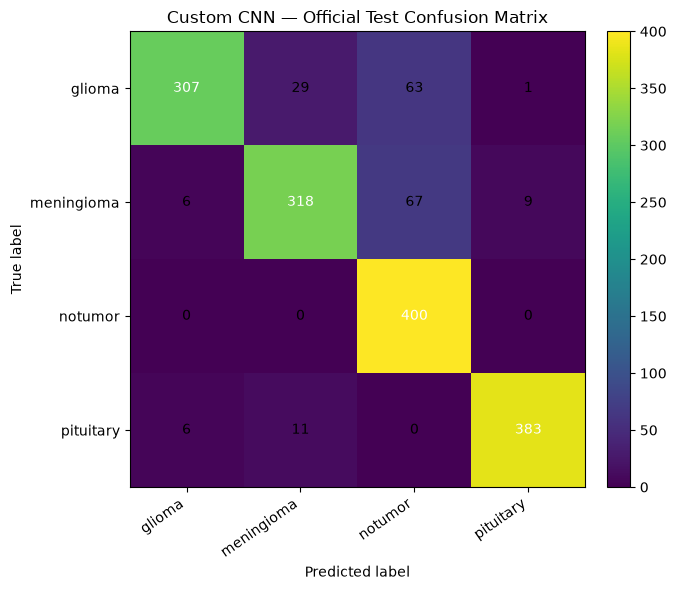

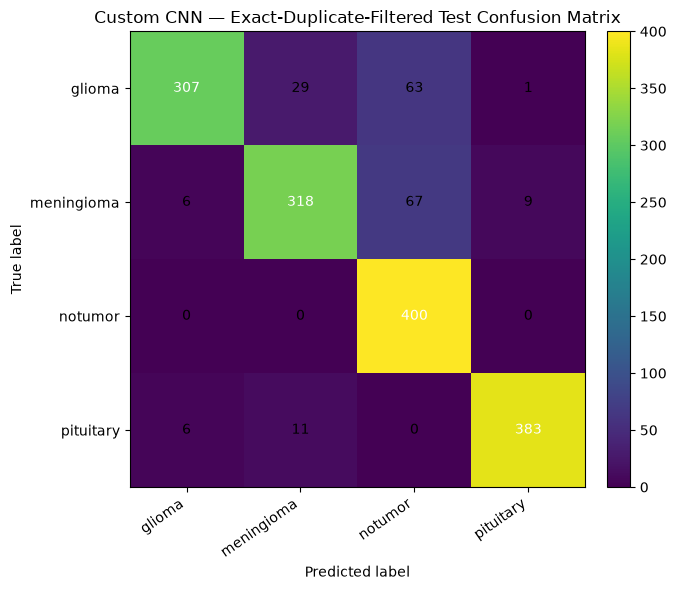

Saved predictions: D:\computer vision\Brain-MRI-Classification\results\custom_cnn_predictions.csv


,evaluation,relative_path,true_class,predicted_class,correct,probability_glioma,probability_meningioma,probability_notumor,probability_pituitary
0,official_test,Testing/glioma/Te-gl_1.jpg,glioma,meningioma,False,0.134501,5.048947e-01,3.107875e-01,4.981715e-02
1,official_test,Testing/glioma/Te-gl_10.jpg,glioma,glioma,True,0.999916,5.230112e-06,7.225631e-05,6.695473e-06
2,official_test,Testing/glioma/Te-gl_100.jpg,glioma,glioma,True,0.999995,4.975516e-08,4.125025e-06,6.343535e-07
3,official_test,Testing/glioma/Te-gl_101.jpg,glioma,glioma,True,0.598058,1.789132e-01,2.217771e-01,1.251643e-03
4,official_test,Testing/glioma/Te-gl_102.jpg,glioma,notumor,False,0.065838,5.817638e-04,9.280495e-01,5.531264e-03
5,official_test,Testing/glioma/Te-gl_103.jpg,glioma,notumor,False,0.000601,1.739201e-03,9.975324e-01,1.278000e-04
6,official_test,Testing/glioma/Te-gl_104.jpg,glioma,meningioma,False,0.470769,5.279811e-01,6.872892e-04,5.626759e-04
7,official_test,Testing/glioma/Te-gl_105.jpg,glioma,glioma,True,0.999996,2.770783e-06,8.860436e-08,1.410385e-06
8,official_test,Testing/glioma/Te-gl_106.jpg,glioma,notumor,False,0.000534,1.034045e-01,8.960614e-01,8.392887e-08
9,official_test,Testing/glioma/Te-gl_107.jpg,glioma,glioma,True,0.999450,5.419641e-04,1.404524e-06,7.002743e-06


In [17]:
class_report = classification_report(
    y_test, pred_test, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0
)
class_report_df = pd.DataFrame(class_report).T
class_report_df.to_csv(REPORT_PATH, index=True)
display(class_report_df.round(4))
print("Saved class-wise report:", REPORT_PATH)

cm_official = save_confusion_matrix(
    y_test, pred_test, CLASS_NAMES,
    "Custom CNN — Official Test Confusion Matrix",
    VIS_DIR / "custom_cnn_confusion_matrix_official_test.png",
)
if filtered_metrics is not None:
    save_confusion_matrix(
        y_filtered, pred_filtered, CLASS_NAMES,
        "Custom CNN — Exact-Duplicate-Filtered Test Confusion Matrix",
        VIS_DIR / "custom_cnn_confusion_matrix_exact_filtered_test.png",
    )

predictions_parts = [official_predictions]
if not filtered_predictions.empty:
    predictions_parts.append(filtered_predictions)
predictions_df = pd.concat(predictions_parts, ignore_index=True)
predictions_df.to_csv(PREDICTIONS_PATH, index=False)
print("Saved predictions:", PREDICTIONS_PATH)
display(predictions_df.head(10))

## 14. Export experiment summary

Keep the generated metrics as-is for reproducibility. Add interpretation in the README only after inspecting the plots and prediction errors. Do not claim a clinical performance level from this dataset.

In [18]:
summary = {
    "model": "CustomBrainMRICNN",
    "seed": int(SEED),
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "dataset_root_relative_to_project": (
        str(DATASET_ROOT.relative_to(PROJECT_ROOT))
        if DATASET_ROOT.is_relative_to(PROJECT_ROOT) else str(DATASET_ROOT)
    ),
    "split_sizes": {
        "train": int(len(train_df)),
        "validation": int(len(val_df)),
        "official_test": int(len(test_df)),
        "test_exact_duplicate_filtered": int(len(test_exact_filtered_df)),
    },
    "validation_split": {
        "method": "StratifiedGroupKFold",
        "selected_fold": int(selected_fold),
        "validation_fraction": float(selected_val_fraction),
        "group_key": "sha256",
        "checkpoint_selection_metric": "validation macro-F1",
    },
    "training_config": {
        "img_size": int(IMG_SIZE),
        "batch_size": int(BATCH_SIZE),
        "epochs_requested": int(EPOCHS),
        "epochs_completed": int(len(history_df)),
        "learning_rate": float(LEARNING_RATE),
        "weight_decay": float(WEIGHT_DECAY),
        "early_stopping_patience": int(EARLY_STOPPING_PATIENCE),
        "device": str(DEVICE),
        "num_parameters": int(num_parameters),
    },
    "best_checkpoint": {
        "path": str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),
        "best_epoch": int(checkpoint["best_epoch"]),
        "best_validation_macro_f1": float(checkpoint["best_validation_macro_f1"]),
    },
    "official_test_metrics": official_metrics,
    "exact_duplicate_filtered_test_metrics": filtered_metrics,
    "data_quality_notes": [
        "Exact-hash groups with conflicting labels were excluded.",
        "Validation splitting keeps exact SHA-256 groups together.",
        "Filtered test removes exact hashes present in original training; it does not remove all near-duplicates.",
        "No reliable patient identifiers are assumed to be available.",
        "This is an educational benchmark, not a clinically validated diagnostic model.",
    ],
}
METRICS_PATH.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
print("Saved experiment summary:", METRICS_PATH)
print(json.dumps(summary, indent=2))

Saved experiment summary: D:\computer vision\Brain-MRI-Classification\results\custom_cnn_metrics.json
{
  "model": "CustomBrainMRICNN",
  "seed": 42,
  "class_names": [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
  ],
  "class_to_idx": {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
  },
  "dataset_root_relative_to_project": "data\\brain-tumor-mri-dataset",
  "split_sizes": {
    "train": 4480,
    "validation": 1120,
    "official_test": 1600,
    "test_exact_duplicate_filtered": 1600
  },
  "validation_split": {
    "method": "StratifiedGroupKFold",
    "selected_fold": 1,
    "validation_fraction": 0.2,
    "group_key": "sha256",
    "checkpoint_selection_metric": "validation macro-F1"
  },
  "training_config": {
    "img_size": 224,
    "batch_size": 32,
    "epochs_requested": 15,
    "epochs_completed": 15,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "early_stopping_patience": 4,
    "device": "cuda",
    "num_parame

## 15. Baseline completion checklist

Before moving to notebook 03, confirm:

- [ ] The dataset inventory and split sizes are plausible.
- [ ] No exact SHA-256 group crosses the train/validation boundary.
- [ ] The best checkpoint was chosen using validation macro-F1.
- [ ] Learning curves and confusion matrices were inspected.
- [ ] The official and exact-duplicate-filtered test metrics were saved, with the data-quality caveats retained.
- [ ] The split manifest `results/model_data_split.csv` exists; notebook 03 should reuse it rather than creating a different split.
- [ ] Actual measured metrics, environment details and any manual exclusions are documented in the project README.

### Next notebook

Proceed to `03_resnet18_transfer_learning.ipynb`. Reuse `results/model_data_split.csv`, `CLASS_NAMES`, and the same evaluation metrics for a fair comparison with this custom CNN. Keep the official test set out of model and hyperparameter selection.